# Results notebook: Distributed Training and Its Carbon Footprint

Loads `results/runs.jsonl` (raw results from `scripts/03_run_experiments.py`), regenerates every table/plot, and states the sizing recommendation. **Run `python scripts/04_analyze.py` first**, or run the cell below.

> If you are looking at smoke-test/synthetic numbers, they are for pipeline testing only and must not be reported.

In [1]:
import os
if not os.path.isdir('scripts'):      # works when launched from notebooks/ or repo root
    os.chdir('..')
import subprocess, sys, json, pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
RUNS = 'results/runs.jsonl'
subprocess.run([sys.executable, 'scripts/04_analyze.py', '--runs', RUNS, '--outdir', 'results'], check=True, capture_output=True)
raw = pd.DataFrame([json.loads(l) for l in open(RUNS) if l.strip()])
print(len(raw), 'runs |', raw.rows_train.max(), 'max train rows | host CPUs:', raw.host_cpus.iloc[0])
raw.groupby(['mode','cores']).size().unstack(0)

30 runs | 801066 max train rows | host CPUs: 22


mode,strong,weak
cores,,
1,3,3
2,3,3
4,3,3
8,3,3
16,3,3


## 1. Experimental setup
- **Hardware:** Intel Core Ultra 9 185H (16 cores: 6 performance + 8 efficient + 2 low-power; 22 threads), 32 GB RAM, Windows 11. "Cluster sizes" are Spark `local[N]` on this one machine.
- **Data:** Criteo Display Advertising Challenge (`dac-v1`), deterministic 1,000,612-row subset (2.2% of 45.8M rows), fixed 80/20 train/test split.
- **Model and run settings:** hashed-feature logistic regression (2^14 buckets, 10 iterations), 1/2/4/8/16 cores, 3 repeats each (30 runs), Spark 3.5.1, CodeCarbon energy measurement.

In [2]:
raw[['spark','platform','hash_bits','max_iter','price_per_vcpu_hour']].drop_duplicates().T

,0
spark,3.5.1
platform,Windows-10-10.0.26200-SP0
hash_bits,14
max_iter,10
price_per_vcpu_hour,0.0480


## 2. Strong scaling (fixed data, more cores)

In [3]:
S = pd.read_csv('results/summary_strong.csv')
S[['cores','fit_s','total_s','speedup_fit','efficiency','cost_usd','energy_kwh','co2e_kg','auc','n_runs']]

,cores,fit_s,total_s,speedup_fit,efficiency,cost_usd,energy_kwh,co2e_kg,auc,n_runs
0,1,59.4708,102.7123,1.0000,1.0000,0.0014,0.0020,0.0014,0.7589,3
1,2,30.4975,57.6339,1.9500,0.9750,0.0015,0.0012,0.0009,0.7589,3
2,4,18.7262,41.0657,3.1758,0.7940,0.0022,0.0010,0.0007,0.7589,3
3,8,14.3355,36.6336,4.1485,0.5186,0.0039,0.0010,0.0007,0.7589,3
4,16,13.5225,41.3900,4.3979,0.2749,0.0088,0.0011,0.0008,0.7589,3


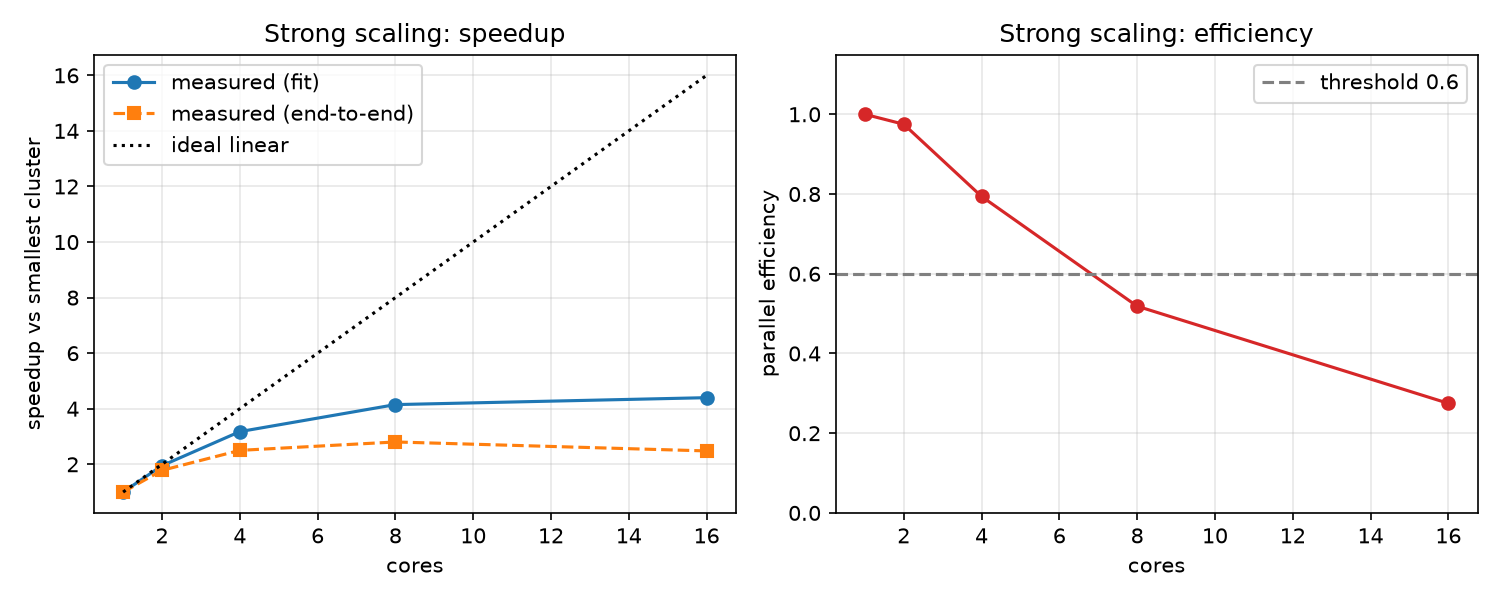

In [4]:
Image('results/strong_scaling.png')

## 3. Weak scaling (data grows with cores)

In [5]:
W = pd.read_csv('results/summary_weak.csv')
W[['cores','rows_train','rows_per_core','fit_s','efficiency','co2e_kg']]

,cores,rows_train,rows_per_core,fit_s,efficiency,co2e_kg
0,1,50079.0000,50079.0000,8.0826,1.0000,0.0004
1,2,100160.0000,50080.0000,8.2567,0.9789,0.0004
2,4,200503.0000,50125.7500,9.4650,0.8539,0.0004
3,8,401104.0000,50138.0000,11.1002,0.7282,0.0006
4,16,801066.0000,50066.6250,13.4419,0.6013,0.0008


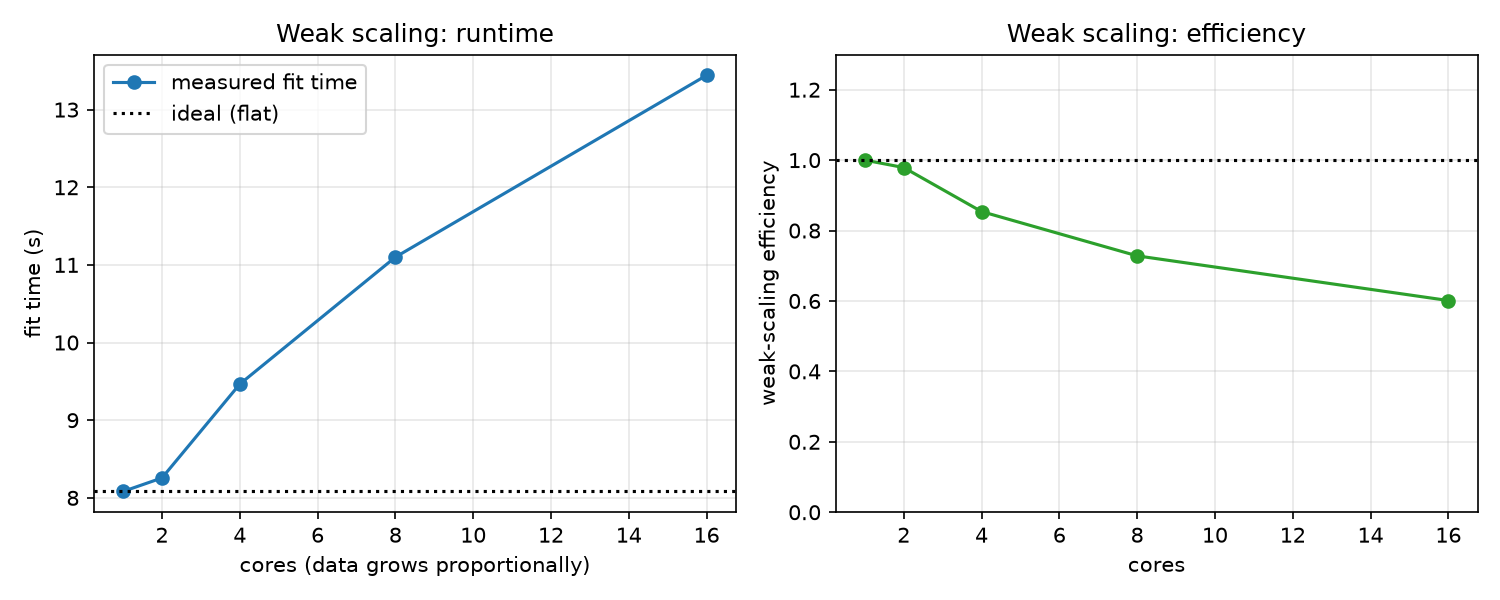

In [6]:
Image('results/weak_scaling.png')

## 4. Cost, energy and carbon

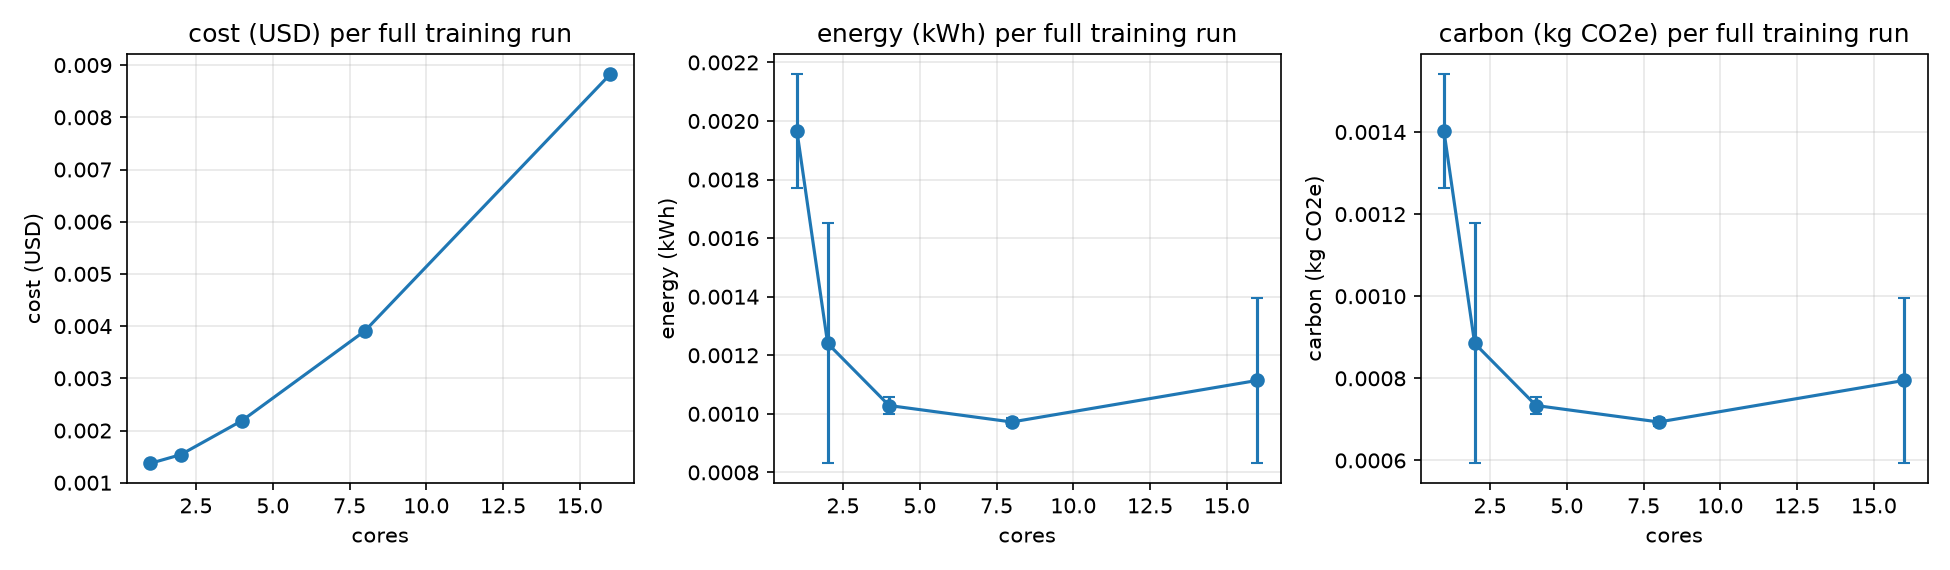

In [7]:
Image('results/cost_carbon.png')

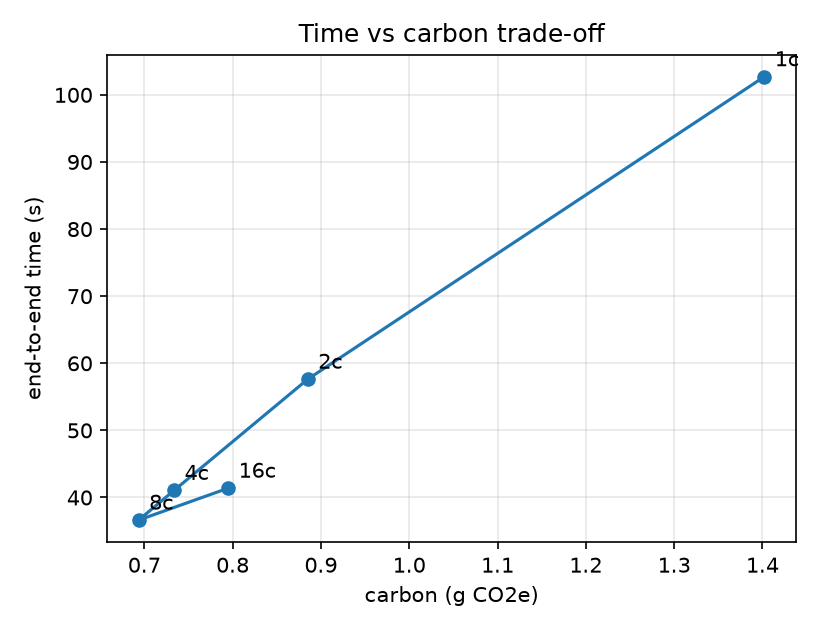

In [8]:
Image('results/tradeoff.png')

## 5. Where do extra machines stop being worthwhile?
Marginal time saved vs extra carbon and cost for each step up in cluster size.

In [9]:
pd.read_csv('results/marginal_analysis.csv')

,from_cores,to_cores,time_saved_s,time_saved_pct,extra_gCO2e,extra_usd,sec_saved_per_extra_gCO2e
0,1,2,45.0785,43.8881,-0.5170,0.0002,inf
1,2,4,16.5682,28.7473,-0.1514,0.0007,inf
2,4,8,4.4321,10.7927,-0.0401,0.0017,inf
3,8,16,-4.7564,-12.9836,0.1014,0.0049,-46.9207


In [10]:
display(Markdown(open('results/recommendation.md').read()))

# Sizing recommendation (auto-generated)

- Baseline cluster: **1 cores**
- Fastest configuration: **8 cores**
- Cheapest configuration: **1 cores**
- Lowest-carbon configuration: **8 cores**
- **Recommended size: 4 cores** - the largest cluster with strong-scaling efficiency >= 0.6 and >= 15% runtime reduction over the previous size.

Beyond this point each added core buys little time while cost and carbon keep rising (see marginal_analysis.csv). **Edit the thresholds in your report to match your own business constraint (deadline, budget, carbon target).**

## Quality guard
AUC range across cluster sizes: 0.7589 - 0.7589 (spread 0.0000). If the spread is tiny, speed was not bought at the cost of accuracy.

## Energy measurement method
Runs by method: codecarbon=30
(`codecarbon` = measured/modelled by CodeCarbon; `tdp_fallback` = CPU-utilisation x TDP estimate.)


## 6. Quality guard (Responsible AI)
Does scaling change model quality overall or on the `I1 missing` slice?

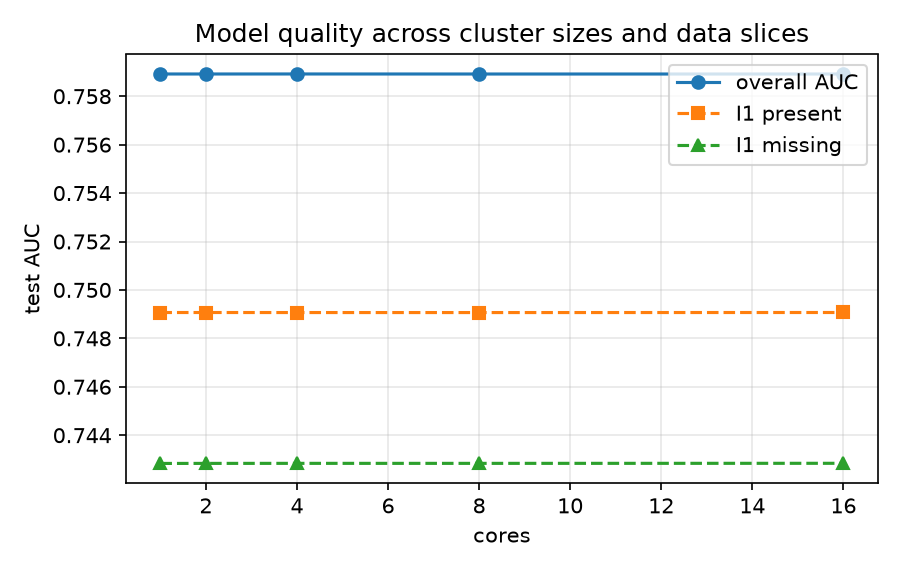

In [11]:
Image('results/slice_auc.png')

## 7. Run-to-run variability
Std-dev of repeated runs. If it is large relative to the differences you claim, say so in the report.

In [12]:
S[['cores','fit_s','fit_s_std','total_s','total_s_std','energy_kwh','energy_kwh_std']]

,cores,fit_s,fit_s_std,total_s,total_s_std,energy_kwh,energy_kwh_std
0,1,59.4708,10.9568,102.7123,10.8586,0.0020,0.0002
1,2,30.4975,14.7121,57.6339,30.1834,0.0012,0.0004
2,4,18.7262,0.3043,41.0657,0.4967,0.0010,0.0000
3,8,14.3355,0.1701,36.6336,0.1538,0.0010,0.0000
4,16,13.5225,0.4565,41.3900,22.9331,0.0011,0.0003


## 8. Conclusions
- **Best size: 4 cores.** It is the largest cluster that keeps strong-scaling efficiency above 0.6 (0.79) and still cuts runtime by at least 15% (28.7% vs 2 cores): 41.1 s end-to-end, $0.0022 and 0.73 g CO2e per run.
- **Returns diminish sharply after 4 cores.** Going 4 to 8 cores saves 10.8% of the time for 78% more cost. Going 8 to 16 cores is 13% slower at 2.3x the cost.
- **Carbon is lowest at 8 cores (0.69 g), about 5% below 4 cores.** Idle machine power is paid every second, so finishing sooner saves energy until extra cores stop shortening the run.
- **Scaling does not change model quality.** AUC is 0.7589 at every cluster size, and the I1-missing slice (0.743) is close to the I1-present slice (0.749).
- **Caveats:** one laptop with simulated clusters (no network cost), 2.2% of the small Criteo set, one model family, and CodeCarbon estimates (use them to compare sizes, not as absolute values). Some runs were disturbed by background load (Section 7).